In [3]:
import numpy as np
import matplotlib.pyplot as plt

import os
from statsmodels.stats.weightstats import DescrStatsW

import numpy as np
import scipy.stats as stats

In [ ]:
def load_process(analysis_method):

    print("DEPRECATED; SEE VERSION BELOW")

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"] 

    resn = "thr"

    weights_all = []
    dg_all = []

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        #--------------------------------------------------------------------------
        #                  load rotamer data for each run

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                rotamer_data = []
                hbond_data = []
                helix_data = []

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    if os.path.exists(rotamer_file):
                        rotamer_data.append(np.load(rotamer_file))

                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    if os.path.exists(hbond_file):
                        hbond_data.append(np.load(hbond_file))

                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"
                    if os.path.exists(secstr_file):
                        helix_data.append(np.load(secstr_file))


                rotamer_data = np.concatenate(rotamer_data, axis = 1)
                hbond_data = np.concatenate(hbond_data, axis = 1)
                helix_data = np.concatenate(helix_data, axis = 1)

                dg, weights, =analysis_method(rotamer_data, hbond_data, helix_data, framerate)
                dg_all.append(dg)
                weights_all.append(weights)
                # import sys
                # sys.exit(0)
                # plt.figure(figsize=(10,10), dpi=600)
                # plt.imshow(rotamer_data[:,0:500])
                # plt.show()


    dg_all = np.concatenate(dg_all)
    weights_all = np.concatenate(weights_all)

    plt.show()
    plt.scatter(weights_all, dg_all)

    plt.show()
    plt.hist(dg_all, weights = weights_all, bins=20, range = (-5,5), density = True)

    dg_mostlyhelical = []
    weights_mostlyhelical = []

    for d, w in zip(dg_all, weights_all):
        if w >= max(weights_all)/2:
            dg_mostlyhelical.append(d)
            weights_mostlyhelical.append(w)

    plt.show()
    plt.hist(dg_mostlyhelical, bins=20, range = (-5,5), density = True)

    print(np.mean(dg_mostlyhelical))

    confidence_level = 0.99
    ci = stats.t.interval(confidence_level, df=len(dg_mostlyhelical)-1, loc=np.mean(dg_mostlyhelical), scale=np.std(dg_mostlyhelical, ddof=1) / np.sqrt(len(dg_mostlyhelical)))
    print(f"{confidence_level*100}% confidence interval: {ci}")

In [58]:
#Question:
#Does solvation (hydrogen bonding with water) shift the rotamer distribution of threonines on helices?

def heatmap_1(rotamer_data, hbond_data, helix_data, framerates):

    #change in delta-g of adopting the 180 degree rotamer between wet and dry conditions
    dg_all = []
    #length of simulation for which residue is on a helix
    weights_all = [] 

    for nr in range(rotamer_data.shape[0]):

        helix_rotamer_hbonds = np.zeros((2,3,3))

        for x,y,z,f in zip(helix_data[nr], rotamer_data[nr], hbond_data[nr], framerates):
            helix_rotamer_hbonds[x,y,z]+=1/f

        r_hb = np.array([[helix_rotamer_hbonds[1,0,0],           np.sum(helix_rotamer_hbonds[1,0,1:3])],
                         [np.sum(helix_rotamer_hbonds[1,1:3,0]), np.sum(helix_rotamer_hbonds[1,1:3,1:3])]])

        #print(np.sum(helix_rotamer_hbonds)/5000)

        #calculate effect of hydrogen bonding with water on rotamer free energy
        #we can't do this calculation unless we have sampled in all four states
        if np.all(r_hb>0): 

            dG_rot_dry = -np.log(r_hb[0,0]/r_hb[1,0])
            dG_rot_wet = -np.log(r_hb[0,1]/r_hb[1,1])

            dg_all.append(dG_rot_wet-dG_rot_dry)
            weights_all.append(np.sum(r_hb))
            #print(np.sum(r_hb)/5000)

    # plt.hist(dg_all, weights = weights_all, bins=20, range = (-5,5), density = True)
    # plt.show()
    print(dg_all)

    confidence_level = 0.95
    ci = stats.t.interval(confidence_level, df=len(dg_all)-1, loc=np.mean(dg_all), scale=np.std(dg_all, ddof=1) / np.sqrt(len(dg_all)))
    print(f"single-protein {confidence_level*100}% confidence interval: {ci}")

    return dg_all, weights_all

#load_process(heatmap_1)

---------------------------------------------:ucp1
[-3.1641713445490147, -1.8681396132618273, -1.4140123881446232, -0.28137064799991407, -0.7002156310382674, 0.18131874001650727, -0.10536051565782635, -0.6029214791376152, -1.8759343560760708, 1.792574396131437, -0.4315230781134711, -1.2882316077557086, -0.4285865170823935, -4.424463324871138, -2.342533874736934, -1.3752015207543398, -0.2970222689873614, 0.6635120334435616, -0.77872922701212, 0.7851217262410932]
single-protein 95.0% confidence interval: (-1.558143983889316, -0.2374450660452866)
---------------------------------------------:aac1
[-3.0359533808782024, -1.649297334520166, -2.7404089933145137, -1.0532457497428256, -1.253908883384136, 0.1056666323642439, -3.0148867320768606]
single-protein 95.0% confidence interval: (-2.9001526339135966, -0.7118572065299633)
---------------------------------------------: overall
each residue used below has at least 30.4057 microseconds of aggregate data in a helix
-3.1641713445490147
1.79257

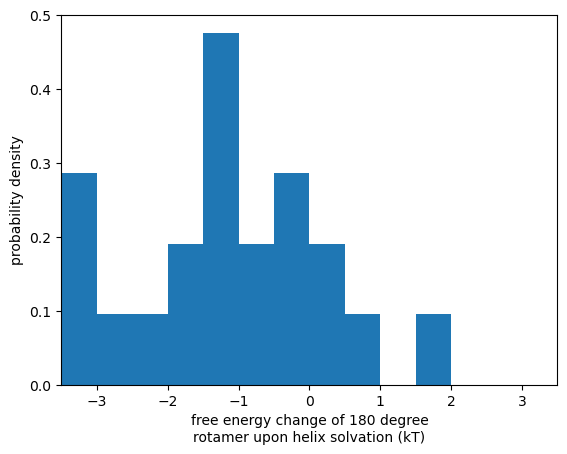

In [68]:
def load_process(analysis_method):

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"]

    resn = "thr"

    weights_all = []
    dg_all = []

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        print("---------------------------------------------:" +protein)
        rotamer_data = []
        hbond_data = []
        helix_data = []
        framerates = []

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"

                    if os.path.exists(rotamer_file) and os.path.exists(hbond_file) and os.path.exists(secstr_file):
                        rotamer_data.append(np.load(rotamer_file))
                        hbond_data.append(np.load(hbond_file))
                        helix_data.append(np.load(secstr_file))
                        framerates.append(framerate*np.ones(rotamer_data[-1].shape[1]))



        rotamer_data = np.concatenate(rotamer_data, axis = 1)
        hbond_data = np.concatenate(hbond_data, axis = 1)
        helix_data = np.concatenate(helix_data, axis = 1)
        framerates = np.concatenate(framerates, axis = 0)


        dg, weights = analysis_method(rotamer_data, hbond_data, helix_data, framerates)
        dg_all.append(dg)
        weights_all.append(weights)


    dg_all = np.concatenate(dg_all)
    weights_all = np.concatenate(weights_all)

    plot_with_alldata = False
    if plot_with_alldata:
        plt.show()
        plt.scatter(weights_all, dg_all)

        plt.show()
        plt.hist(dg_all, weights = weights_all, bins=20, range = (-5,5), density = True)

        confidence_level = 0.99
        ci = stats.t.interval(confidence_level, df=len(dg_all)-1, loc=np.mean(dg_all), scale=np.std(dg_all, ddof=1) / np.sqrt(len(dg_all)))
        print(f"{confidence_level*100}% confidence interval: {ci}")

    dg_mostlyhelical = []
    weights_mostlyhelical = []

    #print(weights_all)

    for d, w in zip(dg_all, weights_all):
        if w >= max(weights_all)*1/2:
            dg_mostlyhelical.append(d)
            weights_mostlyhelical.append(w)

    print("---------------------------------------------: overall")
    print(f"each residue used below has at least {min(weights_mostlyhelical)/5000} microseconds of aggregate data in a helix")

    print(min(dg_mostlyhelical))
    print(max(dg_mostlyhelical))

    plt.show()
    plt.hist(dg_mostlyhelical, bins=14, range = (-3.5,3.5), density = True)
    plt.xlim(-3.5,3.5)
    plt.ylim(0,0.5)
    plt.xlabel("free energy change of 180 degree\nrotamer upon helix solvation (kT)")
    plt.ylabel("probability density")
    plt.savefig(f"figures/{resn}-rotamer-free-energy.png", bbox_inches="tight", dpi=600)
    

    print(f"data for {len(dg_mostlyhelical)} residues")
    print(f"solvation favors 180 degree rotamer by {-np.mean(dg_mostlyhelical):.2f} kT on helices")

    confidence_level = 0.95
    ci = stats.t.interval(confidence_level, df=len(dg_mostlyhelical)-1, loc=np.mean(dg_mostlyhelical), scale=np.std(dg_mostlyhelical, ddof=1) / np.sqrt(len(dg_mostlyhelical)))
    print(f"{confidence_level*100}% confidence interval: {ci}")

load_process(heatmap_1)

In [36]:
#old version with plotting code

#Question:
#Does solvation (hydrogen bonding with water) shift the rotamer distribution of threonines on helices?

def heatmap_1(rotamer_data, hbond_data, helix_data, framerate):

    # dg_wet = []
    # dg_dry = []

    #change in delta-g of adopting the 180 degree rotamer between wet and dry conditions
    dg_all = []
    #length of simulation for which residue is on a helix
    weights_all = [] 

    for nr in range(rotamer_data.shape[0]):

        helix_rotamer_hbonds = np.zeros((2,3,3))

        for x,y,z in zip(helix_data[nr], rotamer_data[nr], hbond_data[nr]):
            helix_rotamer_hbonds[x,y,z]+=1/framerate

        r_hb = np.array([[helix_rotamer_hbonds[1,0,0],           np.sum(helix_rotamer_hbonds[1,0,1:3])],
                         [np.sum(helix_rotamer_hbonds[1,1:3,0]), np.sum(helix_rotamer_hbonds[1,1:3,1:3])]])

        #calculate effect of hydrogen bonding with water on rotamer free energy
        #we can't do this calculation unless we have sampled in all four states
        if np.all(r_hb>0): 

            dG_rot_dry = -np.log(r_hb[0,0]/r_hb[1,0])
            dG_rot_wet = -np.log(r_hb[0,1]/r_hb[1,1])

            dg_all.append(dG_rot_wet-dG_rot_dry)
            weights_all.append(np.sum(r_hb))
            print(np.sum(r_hb)/5000)

        #plotting and debugging code
        # h=1
        # #for h in range(2):
        # if True: #np.sum(helix_rotamer_hbonds[h]) > 0 and nr == 12:
        #     if np.all(r_hb>0): #we can't do this calculation unless we have sampled in all four states

        #         # print(nr)
        #         # print(f"helical fraction: {np.mean(helix_data[h])}")
        #         # # print(helix_rotamer_hbonds[h])
        #         # print(r_hb)

        #         dG_rot_dry = -np.log(r_hb[0,0]/r_hb[1,0])
        #         dG_rot_wet = -np.log(r_hb[0,1]/r_hb[1,1])
                
        #         # dg_wet.append(dG_rot_wet)
        #         # dg_dry.append(dG_rot_dry)

        #         dg_all.append(dG_rot_wet-dG_rot_dry)

        #         #print(dG_rot_wet-dG_rot_dry)

        #         show_all = False
        #         if show_all:
        #             plt.imshow(helix_rotamer_hbonds[h])
        #             #plt.title(f"helix: {h*True}")
        #             plt.ylabel("rotamer")
        #             plt.xlabel("number of hydrogen bonds")
        #             plt.yticks([0,1,2],[180, -60, 60])
        #             plt.xticks([0,1,2],[0,1,2])
        #             plt.show()

        #             plt.imshow(r_hb)
        #             plt.show()
    # print(dg_wet)
    # print(dg_dry)
    # print(dg_all)

    # print(weights_all)
    # print(np.mean(dg_all))
    # plt.hist(dg_all, weights = weights_all, bins=11, range = (-5,5), alpha = 0.2, color="blue")

    return dg_all, weights_all

#load_process(heatmap_1)